# Phần 1: Khám phá và Phân tích Dữ liệu

Mục tiêu của bước này là kiểm tra tính toàn vẹn và mức độ cân bằng của tập dữ liệu huấn luyện. 
Trong bài toán Phân loại nhiều lớp, hiện tượng mất cân bằng dữ liệu thường khiến mô hình bị thiên vị về phía nhãn chiếm đa số, làm suy giảm nghiêm trọng chỉ số F1-Score của các nhãn thiểu số.

Tập dữ liệu sau giai đoạn Data Augmentation gồm **1.215 mẫu**, được thiết kế chia đều cho 5 nhãn ý định:
- `GREETING`: Chào hỏi, tương tác xã giao.
- `TRADE`: Hành vi giao thương, mua bán, kiểm tra giá.
- `INFO`: Yêu cầu thông tin, hướng dẫn nhiệm vụ, chỉ đường.
- `HOSTILE`: Ngôn từ công kích, khiêu khích, thù địch.
- `UNKNOWN`: Các câu truy vấn ngoài luồng, nhiễu hệ thống, spam.

=== BẢNG PHÂN PHỐI DỮ LIỆU HUẤN LUYỆN ===
          Số lượng (Samples)  Tỷ lệ (%)
intent                                 
GREETING                 259      21.32
UNKNOWN                  245      20.16
INFO                     244      20.08
HOSTILE                  238      19.59
TRADE                    229      18.85


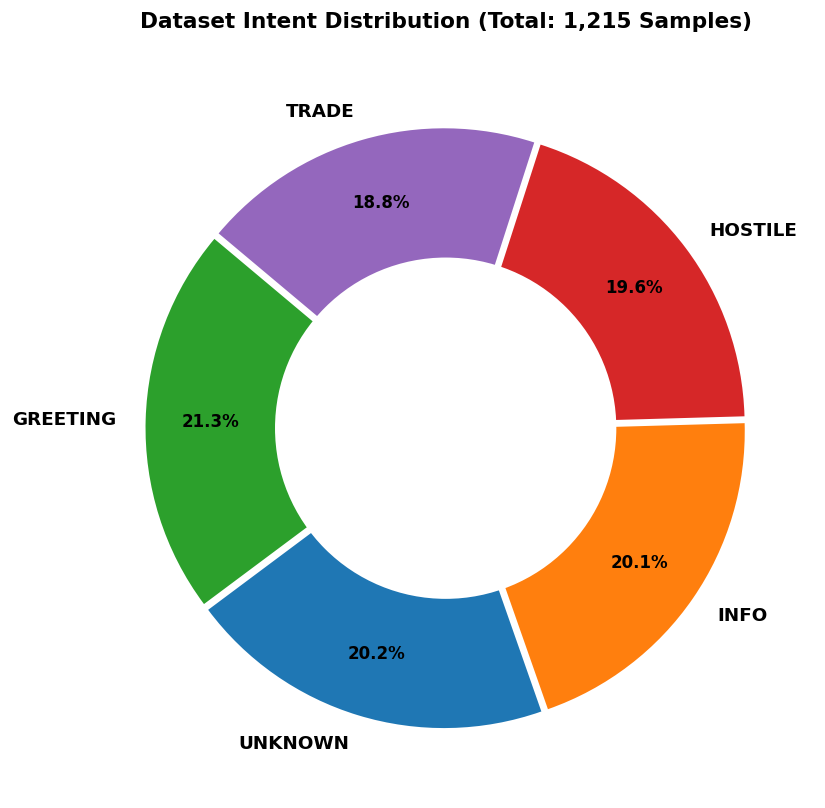

In [ ]:
import json
import pandas as pd
import matplotlib.pyplot as plt

DATASET_PATH = 'train_augmented.json'

with open(DATASET_PATH, 'r', encoding='utf-8') as f:
    raw_data = json.load(f)

df = pd.DataFrame(raw_data)

# Thống kê số lượng và tỷ lệ % mỗi tag Intent
class_counts = df['intent'].value_counts()
class_percentages = df['intent'].value_counts(normalize=True) * 100

summary_table = pd.DataFrame({
    'Số lượng (Samples)': class_counts,
    'Tỷ lệ (%)': class_percentages.round(2)
})
print("=== BẢNG PHÂN PHỐI DỮ LIỆU HUẤN LUYỆN ===")
print(summary_table)

# Trực quan hóa bằng Donut Chart
plt.figure(figsize=(7, 7), dpi=120)

colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728', '#9467bd']
explode = (0.02, 0.02, 0.02, 0.02, 0.02)

wedges, texts, autotexts = plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    explode=explode,
    pctdistance=0.78,
    textprops={'fontsize': 11, 'weight': 'bold'}
)

centre_circle = plt.Circle((0, 0), 0.58, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_circle)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_weight('bold')

plt.title('Dataset Intent Distribution (Total: 1,215 Samples)', fontsize=13, weight='bold', pad=20)
plt.tight_layout()
plt.show()

In [1]:
import json
from sklearn.feature_extraction.text import TfidfVectorizer
import pickle

# 1. Đọc file json data
with open('train_augmented.json', 'r', encoding='utf-8') as f:
    data = json.load(f)

# Tách thành mảng Text (input) và Mảng String Intent (output)
texts = [item['text'] for item in data]
intents = [item['intent'] for item in data]

# 2. Quy đổi Text Label thành Integer Label (từ 0 đến 4)
intent_to_id = {
    "GREETING": 0,
    "TRADE": 1,
    "INFO": 2,
    "HOSTILE": 3,
    "UNKNOWN": 4
}
# array output 
y = [intent_to_id[intent] for intent in intents] 

# 3. Chuyển Text thành mảng Số thực bằng TF-IDF
vectorizer = TfidfVectorizer(max_features=2000) # Lấy 2000 từ phổ biến nhất
# Đây là mảng input số thực X để đưa vào hàm fit()
X = vectorizer.fit_transform(texts) 

print("Kích thước ma trận Input X:", X.shape)
print("Số lượng nhãn Output y:", len(y))

# 4. Lưu lại "Từ điển" Vectorizer này
with open('tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)
print("Đã lưu bộ Vectorizer thành file tfidf_vectorizer.pkl")

Kích thước ma trận Input X: (1215, 1109)
Số lượng nhãn Output y: 1215
Đã lưu bộ Vectorizer thành file tfidf_vectorizer.pkl
